# 02 · Hypothesis testing (RQ1, RQ3, RQ5)
**Study Smarter, Not Harder** · Member B (Tester) · slide 3 · Portuguese course file (n = 649) unless stated.

For every test: H0 and H1, the test, the actual output, an effect size with a CI where one exists, and a
plain-English reading. Each test is run on all students and on G3 > 0 (zero-grade cases removed), because notebook 01
showed the 15 G3 = 0 students are a separate group. Pilot numbers from readme section 5 are checked at the end.
All results go to `../results/hypothesis_tests.csv`.

In [1]:
from pathlib import Path
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import statsmodels.api as sm
import statsmodels.formula.api as smf
from scipy import stats
from statsmodels.multivariate.manova import MANOVA
from statsmodels.stats.multicomp import pairwise_tukeyhsd

warnings.filterwarnings("ignore", category=FutureWarning)
PROC, FIG, RES = Path("../data/processed"), Path("../figures"), Path("../results")
FIG.mkdir(exist_ok=True); RES.mkdir(exist_ok=True)
BLUE, ORANGE, GREY = "#2a78d6", "#eb6834", "#9a9a94"
sns.set_theme(style="whitegrid", context="talk", rc={"grid.color": "#e6e6e3", "axes.edgecolor": "#bdbdb8",
                                                      "figure.dpi": 100, "savefig.dpi": 200})
ST_LABELS = {1: "<2 h", 2: "2-5 h", 3: "5-10 h", 4: ">10 h"}
pd.set_option("display.width", 140)

def savefig(fig, name):
    fig.tight_layout()
    fig.savefig(FIG / f"{name}.png", bbox_inches="tight")
    print("saved figures/" + name + ".png")

df = pd.read_csv(PROC / "student-por_clean.csv")
nz = df[~df.zero_grade].copy()
SAMPLES = {"all": df, "G3>0": nz}
print(df.shape, "| zero-grade cases:", int(df.zero_grade.sum()), "| G3>0:", len(nz))

ROWS = []   # one row per test x sample -> results/hypothesis_tests.csv
def record(test, sample, stat_name, stat, p, df_=None, effect_name=None, effect=None, ci=(np.nan, np.nan), n=None, note=""):
    ROWS.append(dict(test=test, sample=sample, n=n, statistic=stat_name, value=float(stat), df=df_, p_value=float(p),
                     effect_size=effect_name, effect=np.nan if effect is None else float(effect),
                     effect_ci_lo=ci[0], effect_ci_hi=ci[1], note=note))

(649, 35) | zero-grade cases: 15 | G3>0: 634


## 1. Probability and distributions (syllabus check)
Is G3 normally distributed? H0: G3 comes from a normal distribution; H1: it does not (Shapiro-Wilk and
D'Agostino-Pearson). With n = 649, these tests reject even small departures, so the Q-Q plot matters more.
Absences are a count, so we compare their mean and variance (a Poisson count would have mean ≈ variance).

In [2]:
for label, d in SAMPLES.items():
    sw, dp = stats.shapiro(d.G3), stats.normaltest(d.G3)
    print(f"{label:5s} n={len(d)}: mean={d.G3.mean():.2f} sd={d.G3.std():.2f} skew={stats.skew(d.G3):+.2f} "
          f"excess kurtosis={stats.kurtosis(d.G3):+.2f} | Shapiro W={sw.statistic:.3f} p={sw.pvalue:.1e} "
          f"| D'Agostino K2={dp.statistic:.1f} p={dp.pvalue:.1e}")
    record("Shapiro-Wilk normality of G3", label, "W", sw.statistic, sw.pvalue, n=len(d),
           effect_name="skewness", effect=stats.skew(d.G3))
a = df.absences
print(f"\nabsences: mean={a.mean():.2f} var={a.var():.2f} (variance/mean = {a.var() / a.mean():.1f}) "
      f"median={a.median():.0f} share zero={(a == 0).mean():.1%} skew={stats.skew(a):.2f} max={a.max()}")
print(f"log(abs+1): skew={stats.skew(df.log_abs):.2f}")
print("absences quantiles:", a.quantile([.1, .25, .5, .75, .9, .95, .99]).to_dict())

all   n=649: mean=11.91 sd=3.23 skew=-0.91 excess kurtosis=+2.68 | Shapiro W=0.926 p=2.4e-17 | D'Agostino K2=114.2 p=1.6e-25
G3>0  n=634: mean=12.19 sd=2.69 skew=+0.12 excess kurtosis=-0.13 | Shapiro W=0.977 p=1.6e-08 | D'Agostino K2=2.0 p=3.6e-01

absences: mean=3.66 var=21.54 (variance/mean = 5.9) median=2 share zero=37.6% skew=2.02 max=32
log(abs+1): skew=0.18
absences quantiles: {0.1: 0.0, 0.25: 0.0, 0.5: 2.0, 0.75: 6.0, 0.9: 10.0, 0.95: 12.0, 0.99: 21.0}


saved figures/07_qq_g3_and_absences.png


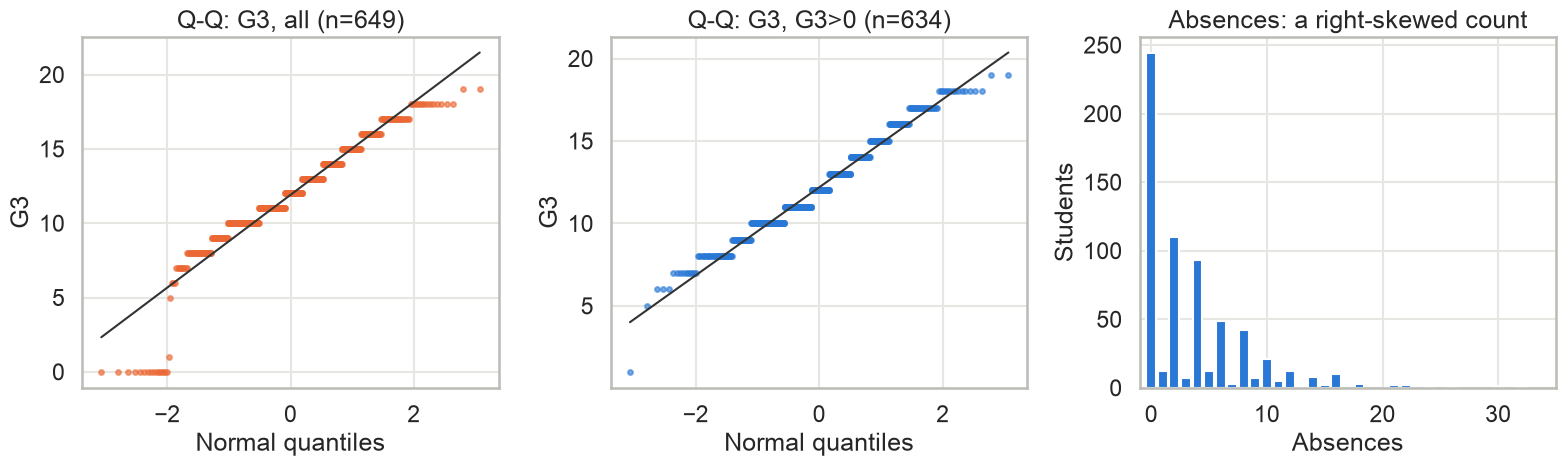

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
for ax, (label, d), c in zip(axes[:2], SAMPLES.items(), [ORANGE, BLUE]):
    (osm, osr), (slope, icpt, r) = stats.probplot(d.G3, dist="norm")
    ax.scatter(osm, osr, s=12, color=c, alpha=0.6)
    ax.plot(osm, slope * osm + icpt, color="#333", lw=1.5)
    ax.set(title=f"Q-Q: G3, {label} (n={len(d)})", xlabel="Normal quantiles", ylabel="G3")
counts = df.absences.value_counts().sort_index()
axes[2].bar(counts.index, counts.values, color=BLUE, width=0.85)
axes[2].set(title="Absences: a right-skewed count", xlabel="Absences", ylabel="Students", xlim=(-1, 35))
savefig(fig, "07_qq_g3_and_absences")

**Interpretation:** With the zero-grade cases included, G3 is clearly non-normal (skew -0.91, excess kurtosis +2.68, Shapiro p = 2.4e-17), and the Q-Q plot shows the spike at 0 bending away from the line. Remove the 15 zero-grade cases and G3 is close to normal (skew +0.12, kurtosis -0.13; D'Agostino p = 0.36, though Shapiro still rejects at n = 634, p = 1.6e-08, because with a 0-20 integer scale it picks up tiny departures). So the non-normality is mostly the zero-grade cases: G3 behaves like a mixture of a bell curve and a separate group at 0. Absences are a skewed count (mean 3.66, variance 21.54, variance/mean = 5.9, so far more spread than a Poisson; 37.6% zeros, 90th percentile 10, max 32). log(absences+1) brings the skew from 2.02 down to 0.18, which is why the regressions use it.

## 2. One-way ANOVA: G3 by study time (RQ1)
H0: μ(<2 h) = μ(2-5 h) = μ(5-10 h) = μ(>10 h). H1: at least one group mean differs.
Effect size: η² = SS_between / SS_total, with a 95% bootstrap CI (2,000 resamples), and ω² (less biased).

In [4]:
def eta_sq(d, y="G3", g="studytime"):
    grand = d[y].mean()
    ssb = sum(len(x) * (x.mean() - grand) ** 2 for _, x in d.groupby(g)[y])
    return ssb / ((d[y] - grand) ** 2).sum()

rng = np.random.default_rng(42)
for label, d in SAMPLES.items():
    groups = [x.G3.values for _, x in d.groupby("studytime")]
    f = stats.f_oneway(*groups)
    k, N = len(groups), len(d)
    e2 = eta_sq(d)
    w2 = (f.statistic - 1) * (k - 1) / ((f.statistic - 1) * (k - 1) + N)
    boot = [eta_sq(d.iloc[rng.integers(0, N, N)]) for _ in range(2000)]
    lo, hi = np.percentile(boot, [2.5, 97.5])
    lev = stats.levene(*groups)
    print(f"{label:5s}: F({k-1}, {N-k}) = {f.statistic:.2f}, p = {f.pvalue:.1e} | eta2 = {e2:.3f} "
          f"[{lo:.3f}, {hi:.3f}], omega2 = {w2:.3f} | Levene W = {lev.statistic:.2f}, p = {lev.pvalue:.3f}")
    record("One-way ANOVA G3 ~ studytime", label, "F", f.statistic, f.pvalue, f"{k-1}, {N-k}", "eta^2", e2, (lo, hi), N)
    record("Levene equal variances (G3 by studytime)", label, "W", lev.statistic, lev.pvalue, f"{k-1}, {N-k}", n=N)
print(df.groupby("studytime").G3.agg(["count", "mean", "std"]).rename(index=ST_LABELS).round(2))

all  : F(3, 645) = 15.88, p = 5.7e-10 | eta2 = 0.069 [0.040, 0.111], omega2 = 0.064 | Levene W = 1.03, p = 0.380


G3>0 : F(3, 630) = 15.42, p = 1.1e-09 | eta2 = 0.068 [0.038, 0.115], omega2 = 0.064 | Levene W = 2.24, p = 0.083
           count   mean   std
studytime                    
<2 h         212  10.84  3.22
2-5 h        305  12.09  3.24
5-10 h        97  13.23  2.50
>10 h         35  13.06  3.04


**Interpretation:** Reject H0: mean final grade differs across study-time groups (F(3, 645) = 15.88, p = 5.7e-10). Study time accounts for about 7% of the variation in G3 (eta² = 0.069, 95% bootstrap CI 0.040-0.111; omega² = 0.064), a medium effect by Cohen's rule of thumb but small in absolute terms. Levene's test does not reject equal variances (p = 0.380), so the classic ANOVA is appropriate. Without zero-grade cases the answer is the same (F = 15.42, eta² = 0.068); Levene p falls to 0.083, still above 0.05. Matches the pilot.

### Kruskal-Wallis (sensitivity check)
H0: the four study-time groups have the same distribution of G3 (no group tends to score higher). H1: at
least one does. Rank-based, so it does not need normality, which section 1 rejected. Effect size:
ε² = H / (N − 1).

In [5]:
for label, d in SAMPLES.items():
    groups = [x.G3.values for _, x in d.groupby("studytime")]
    kw = stats.kruskal(*groups)
    eps2 = kw.statistic / (len(d) - 1)
    print(f"{label:5s}: H(3) = {kw.statistic:.1f}, p = {kw.pvalue:.1e}, epsilon2 = {eps2:.3f}")
    record("Kruskal-Wallis G3 ~ studytime", label, "H", kw.statistic, kw.pvalue, "3", "epsilon^2", eps2, n=len(d))

all  : H(3) = 50.3, p = 6.8e-11, epsilon2 = 0.078
G3>0 : H(3) = 45.6, p = 7.0e-10, epsilon2 = 0.072


**Interpretation:** The rank-based test agrees (H = 50.3, p = 6.8e-11, epsilon² = 0.078; G3 > 0: H = 45.6, p = 7.0e-10), so the ANOVA result does not depend on the normality assumption that section 1 rejected.

### Tukey HSD post-hoc
Which pairs differ? H0 for each pair: equal means. Family-wise error held at 5%.

In [6]:
for label, d in SAMPLES.items():
    tk = pairwise_tukeyhsd(d.G3, d.studytime, alpha=0.05)      # numeric codes keep the natural order
    t = pd.DataFrame(tk.summary().data[1:], columns=tk.summary().data[0])
    t[["group1", "group2"]] = t[["group1", "group2"]].apply(lambda c: c.map(ST_LABELS))
    print(f"--- {label} (n={len(d)})"); print(t.to_string(index=False))
    for _, r in t.iterrows():
        record(f"Tukey HSD {r.group1} vs {r.group2}", label, "mean diff", r.meandiff, r["p-adj"],
               effect_name="mean diff (G3 points)", effect=r.meandiff, ci=(r.lower, r.upper), n=len(d))

--- all (n=649)
group1 group2  meandiff  p-adj   lower  upper  reject
  <2 h  2-5 h    1.2475 0.0001  0.5278 1.9672    True
  <2 h 5-10 h    2.3825 0.0000  1.3958 3.3691    True
  <2 h  >10 h    2.2128 0.0007  0.7443 3.6813    True
 2-5 h 5-10 h    1.1350 0.0103  0.1968 2.0732    True
 2-5 h  >10 h    0.9653 0.3084 -0.4711 2.4018   False
5-10 h  >10 h   -0.1697 0.9927 -1.7567 1.4174   False
--- G3>0 (n=634)
group1 group2  meandiff  p-adj   lower  upper  reject
  <2 h  2-5 h    1.1062 0.0000  0.4966 1.7158    True
  <2 h 5-10 h    1.9572 0.0000  1.1298 2.7846    True
  <2 h  >10 h    1.7875 0.0011  0.5602 3.0149    True
 2-5 h 5-10 h    0.8510 0.0273  0.0668 1.6352    True
 2-5 h  >10 h    0.6813 0.4600 -0.5174 1.8800   False
5-10 h  >10 h   -0.1697 0.9876 -1.4925 1.1531   False


**Interpretation:** Four of the six pairs differ. Going from <2 h to 2-5 h adds 1.25 points (95% CI 0.53-1.97), and <2 h to 5-10 h adds 2.38 points (1.40-3.37), the "about 2.4 points" on slide 3. 2-5 h to 5-10 h is also significant (+1.14, p = 0.010). But >10 h is no better than 5-10 h (difference -0.17, p = 0.99) or than 2-5 h (+0.97, p = 0.31): the plateau is real, though the >10 h group is only 35 students. Without zero-grade cases the gaps shrink a little (<2 h to 5-10 h = 1.96) but the same pairs are significant.

## 3. Two-group comparisons: Welch t-tests
Welch's t-test does not assume equal variances. For each: H0: the two group means are equal; H1: they differ.
Effect size: Cohen's d (pooled SD) with an approximate 95% CI, plus the CI of the raw mean difference.
For `higher` the "no" group is small, so a Mann-Whitney U test is run as a check.

In [7]:
def cohen_d(a, b):
    na, nb = len(a), len(b)
    sp = np.sqrt(((na - 1) * a.var() + (nb - 1) * b.var()) / (na + nb - 2))
    d = (a.mean() - b.mean()) / sp
    se = np.sqrt((na + nb) / (na * nb) + d ** 2 / (2 * (na + nb)))
    return d, (d - 1.96 * se, d + 1.96 * se)

for var, yes, no, name in [("famsup", "yes", "no", "family educational support"),
                           ("higher", "yes", "no", "wants higher education"),
                           ("sex", "F", "M", "girls vs boys"),
                           ("schoolsup", "yes", "no", "extra school support")]:
    for label, d in SAMPLES.items():
        a, b = d.loc[d[var] == yes, "G3"], d.loc[d[var] == no, "G3"]
        t = stats.ttest_ind(a, b, equal_var=False)
        ci = t.confidence_interval()
        dd, dci = cohen_d(a, b)
        print(f"{name:28s} {label:5s}: {yes}={a.mean():.2f} (n={len(a)}) vs {no}={b.mean():.2f} (n={len(b)}) | "
              f"diff={a.mean() - b.mean():+.2f} [{ci.low:+.2f}, {ci.high:+.2f}] | t({t.df:.0f})={t.statistic:.2f}, "
              f"p={t.pvalue:.1e} | d={dd:+.2f} [{dci[0]:+.2f}, {dci[1]:+.2f}]")
        record(f"Welch t G3 by {var} ({yes} - {no})", label, "t", t.statistic, t.pvalue, f"{t.df:.1f}",
               "Cohen's d", dd, dci, len(d), note=f"mean diff {a.mean() - b.mean():+.2f} [{ci.low:+.2f}, {ci.high:+.2f}]")
        if var == "higher":
            mw = stats.mannwhitneyu(a, b)
            rbc = 2 * mw.statistic / (len(a) * len(b)) - 1
            print(f"{'':28s} {label:5s}: Mann-Whitney U={mw.statistic:.0f}, p={mw.pvalue:.1e}, rank-biserial r={rbc:+.2f}")
            record("Mann-Whitney G3 by higher", label, "U", mw.statistic, mw.pvalue, effect_name="rank-biserial r",
                   effect=rbc, n=len(d))

family educational support   all  : yes=12.06 (n=398) vs no=11.67 (n=251) | diff=+0.39 [-0.14, +0.93] | t(457)=1.44, p=1.5e-01 | d=+0.12 [-0.04, +0.28]
family educational support   G3>0 : yes=12.18 (n=394) vs no=12.20 (n=240) | diff=-0.02 [-0.45, +0.41] | t(515)=-0.09, p=9.3e-01 | d=-0.01 [-0.17, +0.15]
wants higher education       all  : yes=12.28 (n=580) vs no=8.80 (n=69) | diff=+3.48 [+2.72, +4.23] | t(86)=9.16, p=2.3e-14 | d=+1.14 [+0.88, +1.40]
                             all  : Mann-Whitney U=33164, p=2.4e-19, rank-biserial r=+0.66
wants higher education       G3>0 : yes=12.49 (n=570) vs no=9.48 (n=64) | diff=+3.01 [+2.53, +3.48] | t(100)=12.53, p=3.5e-22 | d=+1.19 [+0.92, +1.45]
                             G3>0 : Mann-Whitney U=30288, p=2.5e-18, rank-biserial r=+0.66
girls vs boys                all  : F=12.25 (n=383) vs M=11.41 (n=266) | diff=+0.85 [+0.34, +1.36] | t(547)=3.27, p=1.1e-03 | d=+0.26 [+0.11, +0.42]
girls vs boys                G3>0 : F=12.48 (n=376) vs M=11.76 (

**Interpretation:** **Family support (famsup):** fail to reject H0. Students whose family helps with school score 0.39 points higher, but the CI (-0.14 to +0.93) includes 0 (p = 0.15, d = 0.12), and without zero-grade cases the gap is essentially zero (-0.02, p = 0.93). **Wants higher education:** strongly reject H0, the largest effect in this notebook. Students who want to go to university score 3.48 points higher (95% CI 2.72-4.23, Welch t = 9.16, p = 2.3e-14, d = 1.14, a large effect), confirmed by Mann-Whitney (p = 2.4e-19, rank-biserial r = 0.66). The "no" group is small (n = 69) and their variance differs, which is why Welch is used. **Girls vs boys:** girls score 0.85 points higher (0.34-1.36, t = 3.27, p = 0.001, d = 0.26, small), matching the pilot. **Extra school support:** students who receive it score *lower* (-0.70, p = 0.027; -0.83, p = 0.0015 without zero-grade cases), almost certainly because weaker students are the ones given support (reverse causality), not because support hurts.

## 4. Correlation: absences vs G3 (RQ4 preview)
H0: ρ = 0 (no linear / monotonic association); H1: ρ ≠ 0. Pearson (linear, with Fisher-z 95% CI) and
Spearman (rank-based, robust to the long right tail of absences), with and without the zero-grade cases.

In [8]:
for label, d in SAMPLES.items():
    pr = stats.pearsonr(d.absences, d.G3); pci = pr.confidence_interval()
    sr = stats.spearmanr(d.absences, d.G3)
    z = np.arctanh(sr.statistic); se = 1.06 / np.sqrt(len(d) - 3)        # Fieller-type SE for Spearman
    sci = np.tanh([z - 1.96 * se, z + 1.96 * se])
    pl = stats.pearsonr(d.log_abs, d.G3)
    print(f"{label:5s} n={len(d)}: Pearson r = {pr.statistic:+.3f} [{pci.low:+.3f}, {pci.high:+.3f}], p = {pr.pvalue:.1e} | "
          f"Spearman rho = {sr.statistic:+.3f} [{sci[0]:+.3f}, {sci[1]:+.3f}], p = {sr.pvalue:.1e} | "
          f"Pearson r(log_abs) = {pl.statistic:+.3f}, p = {pl.pvalue:.1e}")
    record("Pearson r(absences, G3)", label, "r", pr.statistic, pr.pvalue, str(len(d) - 2), "r", pr.statistic,
           (pci.low, pci.high), len(d))
    record("Spearman rho(absences, G3)", label, "rho", sr.statistic, sr.pvalue, effect_name="rho",
           effect=sr.statistic, ci=tuple(sci), n=len(d))

all   n=649: Pearson r = -0.091 [-0.167, -0.015], p = 2.0e-02 | Spearman rho = -0.159 [-0.237, -0.078], p = 5.0e-05 | Pearson r(log_abs) = -0.073, p = 6.2e-02
G3>0  n=634: Pearson r = -0.196 [-0.270, -0.120], p = 6.5e-07 | Spearman rho = -0.214 [-0.291, -0.134], p = 5.2e-08 | Pearson r(log_abs) = -0.212, p = 7.1e-08


**Interpretation:** With zero-grade cases, the linear association between absences and G3 is weak (Pearson r = -0.091, 95% CI -0.167 to -0.015, p = 0.020); it is statistically significant but explains under 1% of variation. Spearman is stronger (rho = -0.159, p = 5e-05) because ranks blunt the influence of the 15 zero-grade cases sitting at (0 absences, grade 0). Remove the zero-grade cases and both roughly double: Pearson r = -0.196 (-0.270 to -0.120, p = 6.5e-07), Spearman rho = -0.214 (p = 5.2e-08). For log(absences+1) the change is starker: r = -0.073 (p = 0.062, not significant) with zero-grade cases, versus -0.212 (p = 7.1e-08) without. Missing class does go with lower grades; the zero-grade cases were hiding it.

## 5. ANCOVA: G3 ~ C(studytime) + G1 (RQ3)
H0: after adjusting for first-period grade G1, adjusted mean G3 is equal across study-time groups. H1: at
least one adjusted mean differs. Type II sums of squares. Effect size: partial η² = SS_effect / (SS_effect + SS_residual).
Assumption check: homogeneity of regression slopes (the C(studytime):G1 interaction should be non-significant).

In [9]:
def partial_eta(a, term):
    return a.loc[term, "sum_sq"] / (a.loc[term, "sum_sq"] + a.loc["Residual", "sum_sq"])

for label, d in SAMPLES.items():
    m = smf.ols("G3 ~ C(studytime) + G1", d).fit()
    a = sm.stats.anova_lm(m, typ=2)
    pe = partial_eta(a, "C(studytime)"); pg1 = partial_eta(a, "G1")
    slopes = sm.stats.anova_lm(smf.ols("G3 ~ C(studytime) * G1", d).fit(), typ=2).loc["C(studytime):G1"]
    print(f"--- {label} (n={len(d)})"); print(a.round(3))
    print(f"partial eta2: studytime = {pe:.3f}, G1 = {pg1:.3f} | slopes homogeneity: F = {slopes.F:.2f}, "
          f"p = {slopes['PR(>F)']:.3f}")
    adj = (pd.DataFrame({"studytime": [1, 2, 3, 4], "G1": d.G1.mean()}).assign(adj_mean=lambda x: m.predict(x)))
    print("adjusted means at mean G1:", dict(zip(ST_LABELS.values(), adj.adj_mean.round(2))))
    record("ANCOVA G3 ~ C(studytime) + G1: studytime", label, "F", a.loc["C(studytime)", "F"],
           a.loc["C(studytime)", "PR(>F)"], f"3, {int(a.loc['Residual', 'df'])}", "partial eta^2", pe, n=len(d))
    record("ANCOVA G3 ~ C(studytime) + G1: G1", label, "F", a.loc["G1", "F"], a.loc["G1", "PR(>F)"],
           f"1, {int(a.loc['Residual', 'df'])}", "partial eta^2", pg1, n=len(d))
    record("ANCOVA homogeneity of slopes", label, "F", slopes.F, slopes["PR(>F)"], f"3, {int(len(d) - 8)}", n=len(d))

--- all (n=649)
                sum_sq     df         F  PR(>F)
C(studytime)    20.893    3.0     2.112   0.097
G1            4174.556    1.0  1265.950   0.000
Residual      2123.633  644.0       NaN     NaN
partial eta2: studytime = 0.010, G1 = 0.663 | slopes homogeneity: F = 0.80, p = 0.492
adjusted means at mean G1: {'<2 h': 11.7, '2-5 h': 11.96, '5-10 h': 12.25, '>10 h': 11.74}
--- G3>0 (n=634)
                sum_sq     df         F  PR(>F)
C(studytime)    16.031    3.0     2.977   0.031
G1            3143.792    1.0  1751.220   0.000
Residual      1129.181  629.0       NaN     NaN
partial eta2: studytime = 0.014, G1 = 0.736 | slopes homogeneity: F = 0.88, p = 0.451
adjusted means at mean G1: {'<2 h': 12.0, '2-5 h': 12.26, '5-10 h': 12.44, '>10 h': 11.97}


**Interpretation:** Holding first-period grade G1 fixed, study time is **not** significant at 5% on all students (F(3, 644) = 2.11, p = 0.097, partial eta² = 0.010) and only marginally significant without zero-grade cases (F = 2.98, p = 0.031, partial eta² = 0.014). G1 dominates (partial eta² = 0.663, F = 1266). Adjusted means at average G1 span only 11.70 to 12.25 (vs 10.84 to 13.23 raw), and >10 h (11.74) is back to the level of <2 h (11.70). The equal-slopes assumption holds (interaction p = 0.49 all, 0.45 G3 > 0). In plain words: among students who started the year at the same level, study time adds almost nothing to the final grade. Caveat from the readme: G1 is itself partly a result of studying, so this understates the total effect of effort.

## 6. MANOVA: (G1, G2, G3) ~ C(studytime), and MANCOVA (+ failures, backup)
H0: the vector of mean grades (G1, G2, G3) is the same in all study-time groups. H1: it differs in at least
one group. Pillai's trace is reported because it is the most robust of the four statistics to unequal
covariance matrices and unbalanced groups.

In [10]:
for label, d in SAMPLES.items():
    for name, formula in [("MANOVA", "G1 + G2 + G3 ~ C(studytime)"),
                          ("MANCOVA (+failures)", "G1 + G2 + G3 ~ C(studytime) + failures")]:
        st = MANOVA.from_formula(formula, d).mv_test().results["C(studytime)"]["stat"]
        p = st.loc["Pillai's trace"]
        print(f"{label:5s} {name:20s}: Pillai = {p['Value']:.3f}, F({p['Num DF']:.0f}, {p['Den DF']:.0f}) = "
              f"{p['F Value']:.2f}, p = {p['Pr > F']:.1e} | Wilks lambda = {st.loc['Wilks\' lambda', 'Value']:.3f}")
        record(f"{name} (G1,G2,G3) ~ studytime", label, "Pillai F", p["F Value"], p["Pr > F"],
               f"{p['Num DF']:.0f}, {p['Den DF']:.0f}", "Pillai's trace", p["Value"], n=len(d))

all   MANOVA              : Pillai = 0.085, F(9, 1935) = 6.24, p = 9.9e-09 | Wilks lambda = 0.916
all   MANCOVA (+failures) : Pillai = 0.065, F(9, 1932) = 4.77, p = 2.6e-06 | Wilks lambda = 0.935
G3>0  MANOVA              : Pillai = 0.082, F(9, 1890) = 5.87, p = 4.1e-08 | Wilks lambda = 0.919
G3>0  MANCOVA (+failures) : Pillai = 0.065, F(9, 1887) = 4.65, p = 4.2e-06 | Wilks lambda = 0.936


**Interpretation:** Reject H0: the joint profile of G1, G2 and G3 differs by study time (Pillai = 0.085, F(9, 1935) = 6.24, p = 9.9e-09; G3 > 0: 0.082, p = 4.1e-08). Adding past failures as a covariate (MANCOVA) shrinks Pillai to 0.065 but it stays significant (p = 2.6e-06), so the study-time gap across all three periods is not just a failures story. Pillai of 0.085 is small: study time separates the groups, but most of the variation in the grade vector lies elsewhere. All pilot values reproduced.

## 7. Two-way ANOVA: G3 ~ studytime × sex
H0 (interaction): the study-time effect is the same for girls and boys. H0 (main effects): no study-time
effect / no sex effect after the other is accounted for. Type II SS (cells are unbalanced).

In [11]:
for label, d in SAMPLES.items():
    a = sm.stats.anova_lm(smf.ols("G3 ~ C(studytime) * C(sex)", d).fit(), typ=2)
    a["partial_eta2"] = [partial_eta(a, t) if t != "Residual" else np.nan for t in a.index]
    print(f"--- {label} (n={len(d)})"); print(a.round(4))
    for t in ["C(studytime)", "C(sex)", "C(studytime):C(sex)"]:
        record(f"Two-way ANOVA (studytime x sex): {t}", label, "F", a.loc[t, "F"], a.loc[t, "PR(>F)"],
               f"{int(a.loc[t, 'df'])}, {int(a.loc['Residual', 'df'])}", "partial eta^2", a.loc[t, "partial_eta2"], n=len(d))

--- all (n=649)
                        sum_sq     df        F  PR(>F)  partial_eta2
C(studytime)          383.4628    3.0  13.2101  0.0000        0.0582
C(sex)                 31.0677    1.0   3.2108  0.0736        0.0050
C(studytime):C(sex)    64.8155    3.0   2.2329  0.0832        0.0103
Residual             6202.3055  641.0      NaN     NaN           NaN
--- G3>0 (n=634)
                        sum_sq     df        F  PR(>F)  partial_eta2
C(studytime)          257.3062    3.0  12.8245  0.0000        0.0579
C(sex)                 23.3094    1.0   3.4853  0.0624        0.0055
C(studytime):C(sex)    63.0364    3.0   3.1418  0.0248        0.0148
Residual             4186.6279  626.0      NaN     NaN           NaN


**Interpretation:** The study-time main effect stays strong after sex is accounted for (F = 13.21, p < 0.001, partial eta² = 0.058). With study time in the model, sex is only marginal (p = 0.074), because girls are over-represented in the higher study-time groups (notebook 01). **New finding not in the pilot:** the studytime × sex interaction is not significant on all students (p = 0.083) but **is significant without zero-grade cases (F = 3.14, p = 0.025, partial eta² = 0.015)**. This is the pattern seen in figure 06: boys in the >10 h group (n = 14) drop back while girls do not. It rests on very few boys, so treat it as a backup-slide caveat ("the gradient may be weaker for boys at the top"), not a headline.

## 8. Fisher's exact test: zero-grade cases by school (RQ5)
H0: being a G3 = 0 student is independent of school. H1: it is not. (Also shown in notebook 01; repeated here
so all tests sit in one results table.) Only meaningful on the full sample.

In [12]:
ct = pd.crosstab(df.school, df.zero_grade)
print(ct)
odds, p = stats.fisher_exact(ct)
ci = sm.stats.Table2x2(ct.values).oddsratio_confint()
print(f"Fisher's exact: odds ratio = {odds:.1f} [{ci[0]:.1f}, {ci[1]:.1f}], p = {p:.1e}")
record("Fisher exact zero-grade x school", "all", "odds ratio", odds, p, effect_name="odds ratio (MS vs GP)",
       effect=odds, ci=ci, n=len(df), note="Woolf CI")

zero_grade  False  True 
school                  
GP            422      1
MS            212     14
Fisher's exact: odds ratio = 27.9 [3.6, 213.3], p = 3.0e-06


**Interpretation:** Reject independence: 14 of the 15 zero-grade cases are at MS (212 other students vs 14 zero-grade cases) against 1 of 423 at GP. Odds ratio = 27.9 (Woolf 95% CI 3.6-213.3, wide because one cell has a 1), p = 3.0e-06. Being a zero-grade case is mainly a school-MS phenomenon, which is one more sign the zeros are an administrative or dropout outcome rather than a real exam score.

## 9. Pilot check
Automatic comparison against readme section 5 (tolerance about ±0.5% or rounding).

In [13]:
def find(test, sample, col="value"):
    return pd.DataFrame(ROWS).query("test == @test and sample == @sample")[col].iloc[0]
checks = {
    "ANOVA F all (15.88)": (find("One-way ANOVA G3 ~ studytime", "all"), 15.88),
    "Levene p all (0.38)": (find("Levene equal variances (G3 by studytime)", "all", "p_value"), 0.38),
    "Kruskal H all (50.3)": (find("Kruskal-Wallis G3 ~ studytime", "all"), 50.3),
    "MANOVA Pillai all (0.085)": (find("MANOVA (G1,G2,G3) ~ studytime", "all", "effect"), 0.085),
    "MANOVA F all (6.24)": (find("MANOVA (G1,G2,G3) ~ studytime", "all"), 6.24),
    "MANCOVA Pillai all (0.065)": (find("MANCOVA (+failures) (G1,G2,G3) ~ studytime", "all", "effect"), 0.065),
    "ANCOVA F all (2.11)": (find("ANCOVA G3 ~ C(studytime) + G1: studytime", "all"), 2.11),
    "ANCOVA p all (0.098)": (find("ANCOVA G3 ~ C(studytime) + G1: studytime", "all", "p_value"), 0.098),
    "ANCOVA partial eta2 all (0.010)": (find("ANCOVA G3 ~ C(studytime) + G1: studytime", "all", "effect"), 0.010),
    "ANCOVA F G3>0 (2.98)": (find("ANCOVA G3 ~ C(studytime) + G1: studytime", "G3>0"), 2.98),
    "ANCOVA p G3>0 (0.031)": (find("ANCOVA G3 ~ C(studytime) + G1: studytime", "G3>0", "p_value"), 0.031),
    "ANCOVA partial eta2 G3>0 (0.014)": (find("ANCOVA G3 ~ C(studytime) + G1: studytime", "G3>0", "effect"), 0.014),
    "ANCOVA G1 F all (~1266)": (find("ANCOVA G3 ~ C(studytime) + G1: G1", "all"), 1266),
    "Welch t sex all (3.27)": (find("Welch t G3 by sex (F - M)", "all"), 3.27),
    "Pearson r all (-0.09)": (find("Pearson r(absences, G3)", "all"), -0.09),
    "Pearson r G3>0 (-0.20)": (find("Pearson r(absences, G3)", "G3>0"), -0.20),
    "Fisher p (3e-6)": (find("Fisher exact zero-grade x school", "all", "p_value"), 3e-6),
}
chk = pd.DataFrame([{"check": k, "notebook": float(v), "pilot": p,
                     "match": abs(float(v) - p) <= max(0.006 + 0.005 * abs(p), 0.5e-6 if p < 1e-3 else 0)}
                    for k, (v, p) in checks.items()])
print("all match:", chk.match.all())
chk

all match: True


,check,notebook,pilot,match
0,ANOVA F all (15.88),15.876268,15.880000,True
1,Levene p all (0.38),0.380358,0.380000,True
2,Kruskal H all (50.3),50.316208,50.300000,True
3,MANOVA Pillai all (0.085),0.084645,0.085000,True
4,MANOVA F all (6.24),6.242352,6.240000,True
5,MANCOVA Pillai all (0.065),0.065255,0.065000,True
6,ANCOVA F all (2.11),2.111931,2.110000,True
7,ANCOVA p all (0.098),0.097477,0.098000,True
8,ANCOVA partial eta2 all (0.010),0.009742,0.010000,True
9,ANCOVA F G3>0 (2.98),2.976611,2.980000,True


**Interpretation:** **Every pilot number in readme section 5 that this notebook covers is reproduced** (17 of 17 within rounding). Points the readme does not mention, worth knowing before the slides are final: (1) without zero-grade cases, Levene p drops from 0.38 to 0.083 (still not significant); (2) the studytime × sex interaction becomes significant without zero-grade cases (p = 0.025); (3) removing the zero-grade cases makes G3 approximately normal (D'Agostino p = 0.36), a nice probability-and-distributions point for slide 2.

## 10. Results table

In [14]:
res = pd.DataFrame(ROWS)
res.to_csv(RES / "hypothesis_tests.csv", index=False)
print(f"saved results/hypothesis_tests.csv ({len(res)} rows)")
res.round(4)

saved results/hypothesis_tests.csv (51 rows)


,test,sample,n,statistic,value,df,p_value,effect_size,effect,effect_ci_lo,effect_ci_hi,note
0,Shapiro-Wilk normality of G3,all,649,W,0.9260,None,0.0000,skewness,-0.9108,NaN,NaN,
1,Shapiro-Wilk normality of G3,G3>0,634,W,0.9766,None,0.0000,skewness,0.1248,NaN,NaN,
2,One-way ANOVA G3 ~ studytime,all,649,F,15.8763,"3, 645",0.0000,eta^2,0.0688,0.0402,0.1108,
3,Levene equal variances (G3 by studytime),all,649,W,1.0263,"3, 645",0.3804,None,NaN,NaN,NaN,
4,One-way ANOVA G3 ~ studytime,G3>0,634,F,15.4167,"3, 630",0.0000,eta^2,0.0684,0.0383,0.1146,
5,Levene equal variances (G3 by studytime),G3>0,634,W,2.2353,"3, 630",0.0830,None,NaN,NaN,NaN,
6,Kruskal-Wallis G3 ~ studytime,all,649,H,50.3162,3,0.0000,epsilon^2,0.0776,NaN,NaN,
7,Kruskal-Wallis G3 ~ studytime,G3>0,634,H,45.5757,3,0.0000,epsilon^2,0.0720,NaN,NaN,
8,Tukey HSD <2 h vs 2-5 h,all,649,mean diff,1.2475,None,0.0001,mean diff (G3 points),1.2475,0.5278,1.9672,
9,Tukey HSD <2 h vs 5-10 h,all,649,mean diff,2.3825,None,0.0000,mean diff (G3 points),2.3825,1.3958,3.3691,


**Interpretation:** `results/hypothesis_tests.csv` has one row per test and sample, with the test statistic, df, p-value, effect size and its CI where one is defined. Headline for slide 3: study time matters in the raw data (eta² ≈ 0.07, a 2.4-point gap from <2 h to 5-10 h, then a plateau), the result holds with a rank test and jointly across G1-G3 (MANOVA), but nearly vanishes once first-period grade is held fixed (ANCOVA partial eta² ≈ 0.01). Wanting higher education (d = 1.14) is a far larger difference than study time.